# MID-REVIEW DEMONSTRATION

### Project: Reinforcement Learning for Drug-Likeness Optimization of Small Molecules



In [1]:
import torch
import sys
import os
import pandas as pd
sys.path.append(os.path.abspath(".."))
from rdkit import Chem
from rdkit.Chem import Draw
from implementation.environment import MolecularEnvironment
from implementation.properties import calculate_properties

### 1. Select a Molecule from ZINC

Original SMILES: Cc1ccc(C(=O)Nc2ccc(N3CCCC3=O)cc2)cc1[N+](=O)[O-]


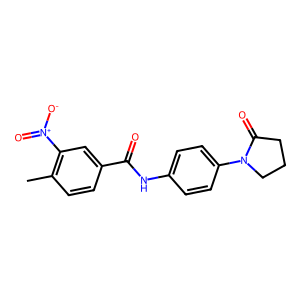

In [2]:
try:
    df = pd.read_csv("../data/processed/zinc_processed.csv", nrows=100)
except FileNotFoundError:
    # Fallback to original dataset if processed not yet saved
    df = pd.read_csv("../ZINC-250K/250k_rndm_zinc_drugs_clean_3.csv", nrows=100)
    
start_smiles = df.iloc[42]["smiles"].strip()
start_mol = Chem.MolFromSmiles(start_smiles)
print("Original SMILES:", start_smiles)
display(Draw.MolToImage(start_mol))

### 2. Calculate Initial Properties

In [3]:
initial_props = calculate_properties(start_mol)
print(f"Original QED: {initial_props['qed']:.4f}")
print(f"Original SAS: {initial_props['sas']:.4f}")

Original QED: 0.6832
Original SAS: 1.9375


### 3. Initialize Environment & Perform Edit
We will attempt to add a Fluorine atom to the first atom (index 0).

In [4]:
env = MolecularEnvironment()
obs, _ = env.reset(options={"starting_smiles": start_smiles})

# Let's add a Fluorine (element index 3 in [C, N, O, F, S, Cl]) to atom 0
action = {"type": 0, "atom1": 0, "atom2": 0, "element": 3, "bond_delta": 1}
next_obs, reward, done, _, info = env.step(action)

print("Valid Edit Attempted.")

Valid Edit Attempted.


### 4. Display Resulting Molecule & Properties

Modified SMILES: O=C(Nc1ccc(N2CCCC2=O)cc1)c1ccc(CF)c([N+](=O)[O-])c1
New QED: 0.6552
New SAS: 2.2114
Tanimoto Similarity: 0.7368
Chemically Valid: True
Reward Received: -0.0380


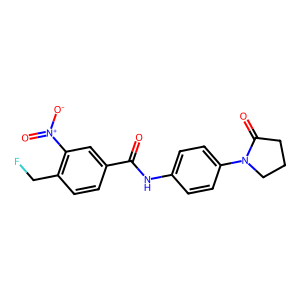

In [5]:
new_mol = env.current_mol
modified_smiles = Chem.MolToSmiles(new_mol)

print("Modified SMILES:", modified_smiles)
print(f"New QED: {next_obs['qed'][0]:.4f}")
print(f"New SAS: {next_obs['sas'][0]:.4f}")
print(f"Tanimoto Similarity: {next_obs['similarity'][0]:.4f}")
print(f"Chemically Valid: {info.get('invalid_penalty') is None}")
print(f"Reward Received: {reward:.4f}")

display(Draw.MolToImage(new_mol))